# Lecture 21 notebook: replaying the exchange

This notebook replays Lecture 21 on Bybit's BTCUSDT perpetual. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | Three replays of one order: the key chart | §1 |
| 2 | The pieces on invented data, and our code against the published rules | §2 |
| 3 | The replay on our data: clocks, latency, the queue, adverse fills | §3 |
| 4 | Does the replay tell the truth? The tests and the verdicts | §4 |
| 5 | 10 October: the replay in the cascade | §5 |
| 6 | A test of your own: the position against the fills | §6.3 |

**Two switches, both off by default.** Heavy steps run only when you switch them on in §0.

* **Off (default): the figures and tables only.** All 15 figures and the tables of the tests are redrawn from the small results shipped in `results/`, and match the lecture's. No market data is needed; it takes about a minute, most of it for saving the pictures.
* **`RUN_CHECK = True`: one day.** The key chart's order, the hidden flow, the held orders and the two quoters are rerun on `CHECK_DAY` and compared with the lecture's values for that day. It needs the Parquet tables of Lecture 18 for `CHECK_DAY` (`BYBIT_ROOT`, default `data/bybit` at the top of the repository), and Lecture 19's book state, which is built if missing. It took about four minutes on a laptop, once the book state exists.
* **`RUN_ALL = True`: everything.** Every measure is recomputed on the days in the data folder, the tests are rerun, and the figures are drawn from the new results. On the 45 days of the lecture (20 September – 3 November 2025) this is a job of about a day and has not been timed as one run: the steps were run in parts. Each step waits when free memory is short, and days already done are skipped, so it can be stopped and resumed.

Results go to `BYBIT_ROOT/interim/l21` (or `L21_OUT`); figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never overwritten.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
OTHER = {19: HERE.parent / "19-statistics-of-the-book" / "scripts", 21: SCRIPTS}
sys.path[:0] = [str(SCRIPTS)]
import l21 as L
CHECK_DAY = "2025-10-01"                                                   # the day on which the measures are rerun (the day of the key chart)
RUN_CHECK = False                                                          # True: rerun on CHECK_DAY (about four minutes)
RUN_ALL = False                                                            # True: recompute everything on every day (about a day)
CRASH = "2025-10-10"

pl.Config.set_tbl_rows(50); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200); pl.Config.set_tbl_cols(20)
DAYS = sorted(p.stem for p in L.BOOK.glob("*.parquet")) if L.BOOK.exists() else []
print("data folder:", L.ROOT, "| results:", L.OUT)
print("days with a book:", len(DAYS), (DAYS[0], DAYS[-1]) if DAYS else "")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, lecture=21, show=False):
    "Run a script of this lecture (or, unchanged, of Lecture 19) in a fresh process; figures as nb_*, results to the L*_OUT folders."
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.ROOT), "L19_OUT": str(L.STATE.parent), "L21_OUT": str(L.OUT), "L19_PREFIX": "nb_", "L21_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(OTHER[lecture] / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def state(d):
    "Lecture 19's book state of day d, built with its own script if missing."
    if not (L.STATE / f"{d}.parquet").exists(): run("l19_state.py", d, lecture=19)


def table(folder, name):
    "A result: computed here if there, otherwise as shipped with the lecture."
    return pl.read_parquet(L.result_path(L.OUT / folder, name))


def shipped(folder, name):
    "A result as shipped with the lecture (results/<folder>/), for comparison with the rerun."
    return pl.read_parquet(L.RESULTS / folder / name)


def compare(rows):
    "rows: (measure, lecture's value, this run's value)."
    return pl.DataFrame([(m, float(a), float(b)) for m, a, b in rows], schema=["measure", "lecture", "this run"], orient="row")


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


if RUN_ALL:
    for d in DAYS: state(d)
elif RUN_CHECK: state(CHECK_DAY)

data folder: data\bybit | results: interim/l21 or results/, as shipped
days with a book: 0 


## 1. Three replays of one order

Figure 21_01 is the plan of Part IV. Figure 21_02, the key chart, follows one resting bid of 0.001 BTC on 1 October 2025 under the touch, queue and trade-through rules, and then the same order every 15 s of that day. With `RUN_CHECK`, the moment and the day are recomputed from the book and the trades; otherwise the chart is drawn from the results shipped.

l21_s1_charts.py : 6 s


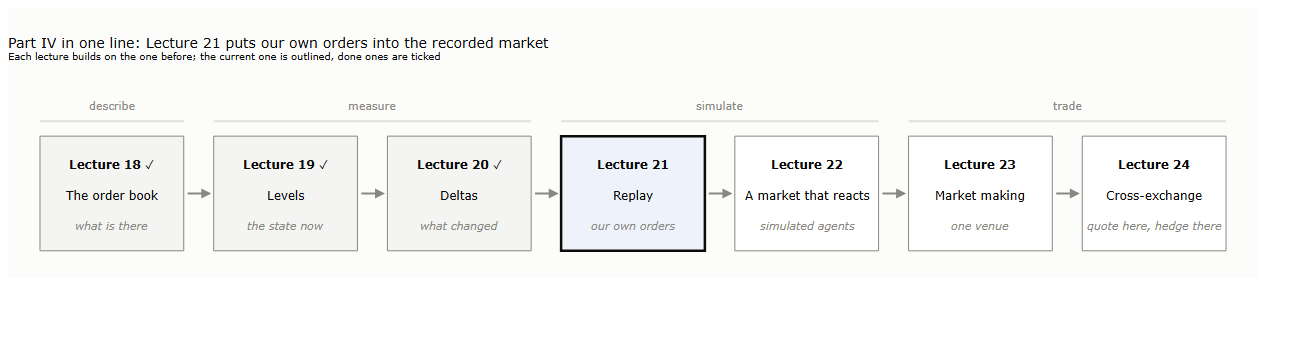

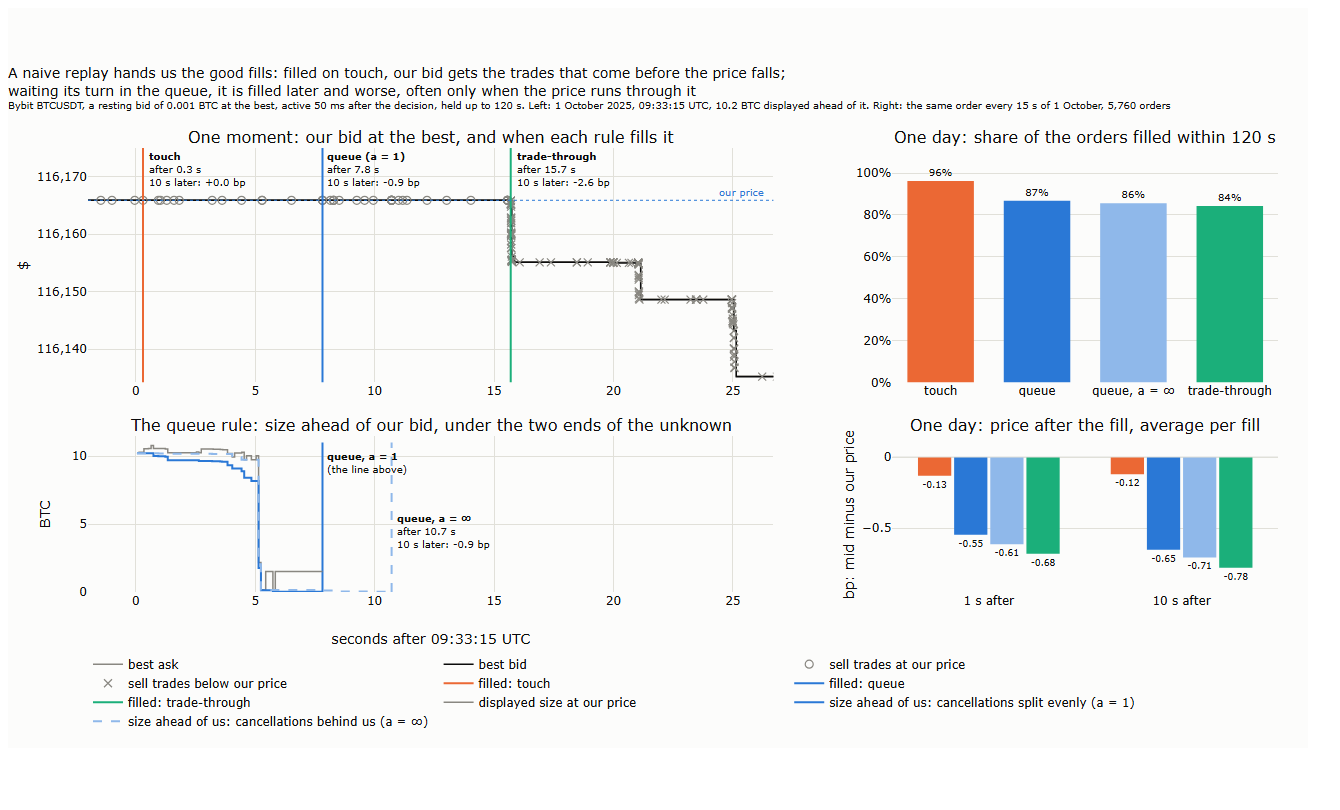

In [2]:
if RUN_CHECK or RUN_ALL: run("l21_s1_key.py")
run("l21_s1_charts.py")
pictures("21_01_part_iv", "21_02_three_replays")
if RUN_CHECK or RUN_ALL:
    a, b = shipped("key", "day_orders.parquet"), pl.read_parquet(L.KEY / "day_orders.parquet")
    display(compare([(f"mean of {c}", a[c].cast(pl.Float64).mean(), b[c].cast(pl.Float64).mean()) for c in a.columns if a[c].dtype.is_numeric()]))

## 2. The pieces on invented data

The cards of §2 use invented data, so that what each piece does is clear before it meets the market: what a replay is (21_03), the latency gap (21_04), the queue (21_05, 21_06), adverse fills (21_07), our footprint (21_08) and the life of one order (21_09). The two checks then run our queue rule, first on the invented example whose answers are known by hand, then against the rules of hftbacktest and Rigtorp (2013), written literally, on 3,000 random sequences (§2.3).

l21_s2_cards.py : 16 s


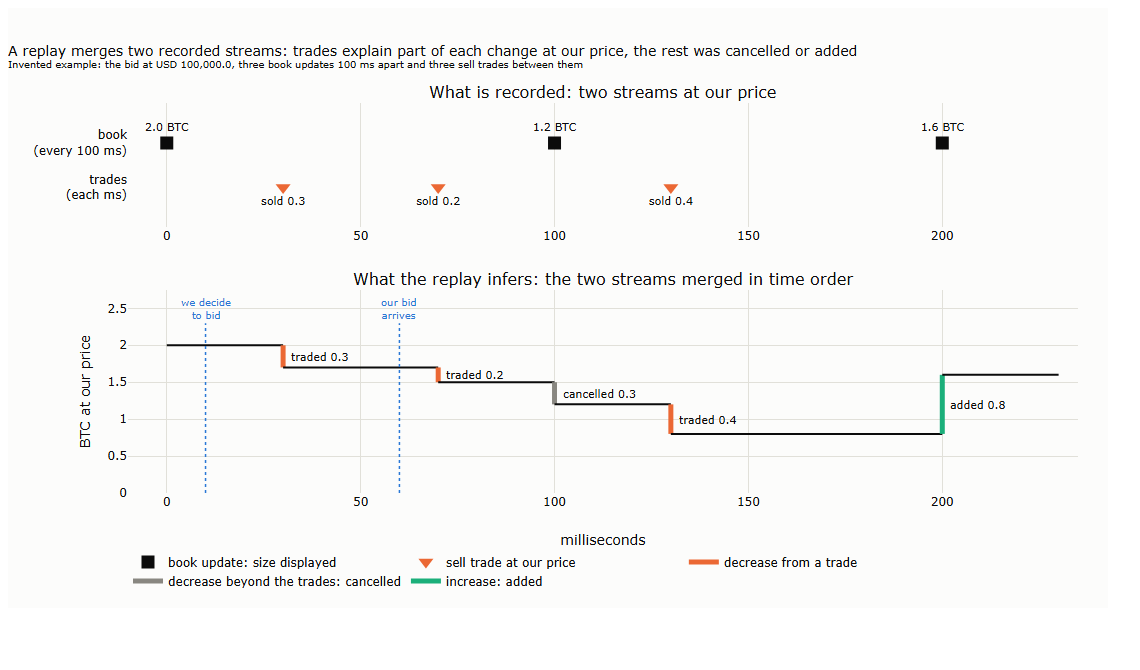

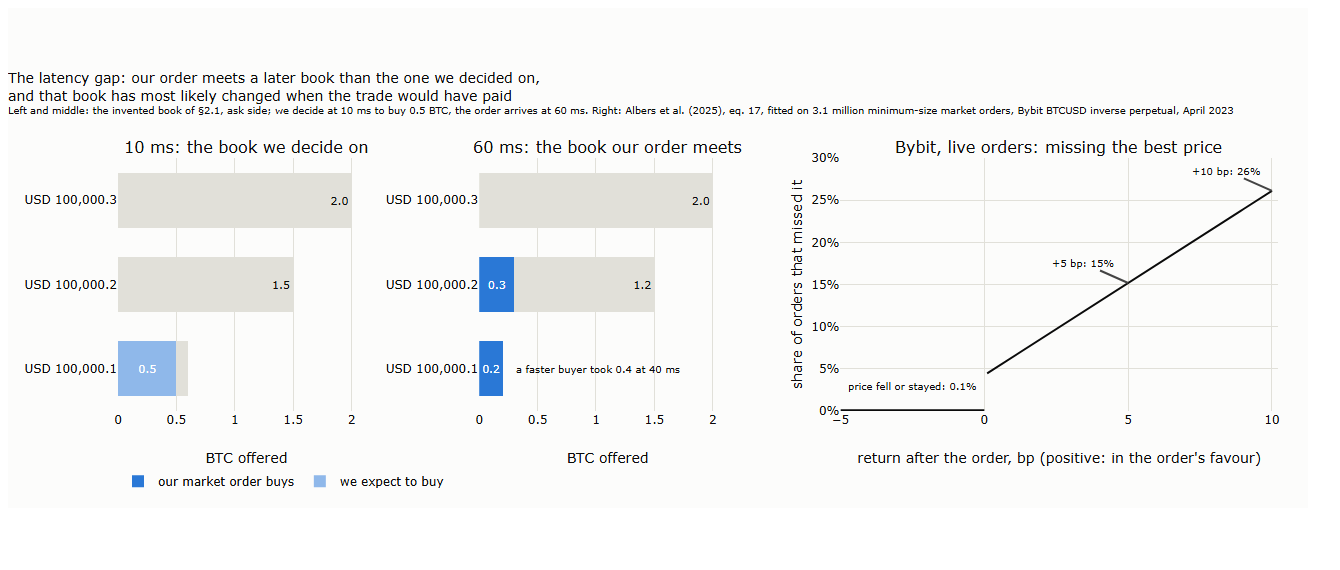

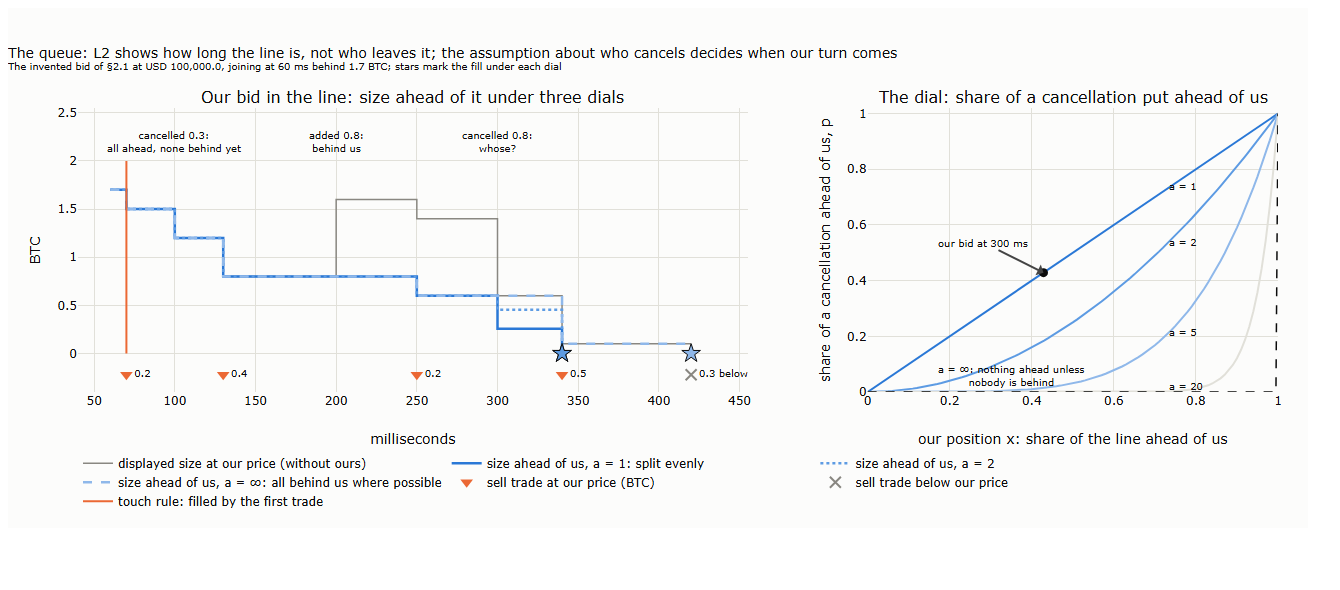

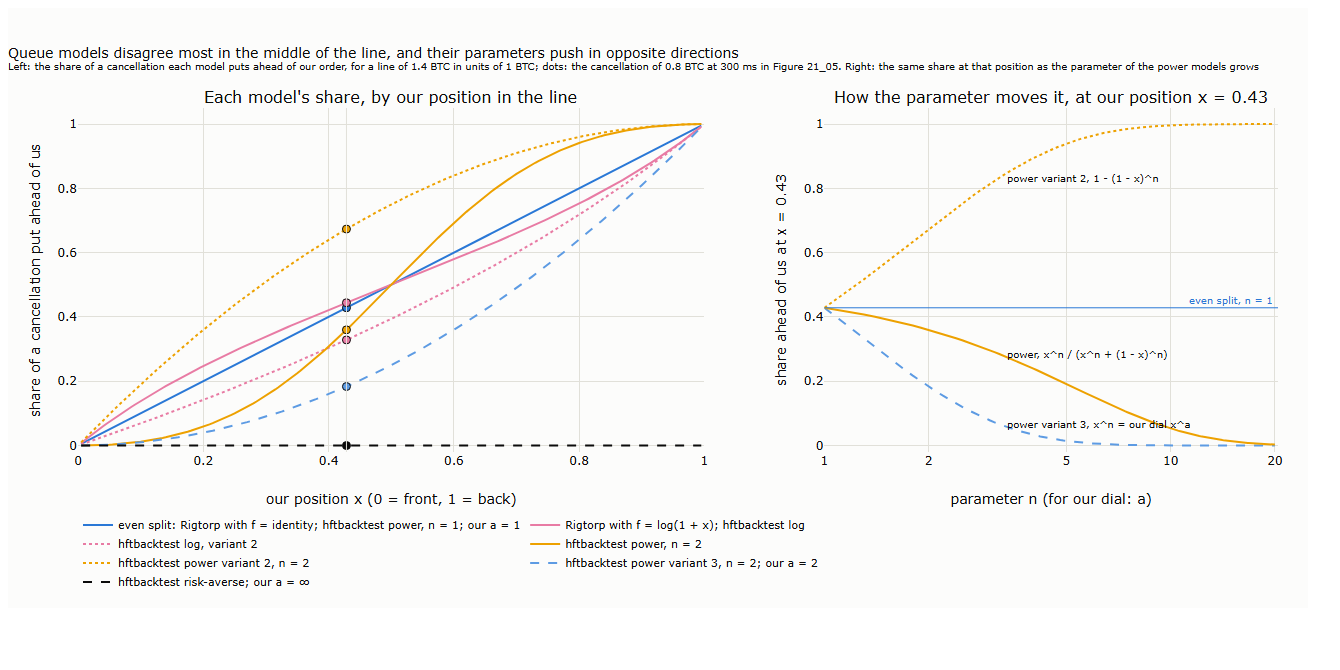

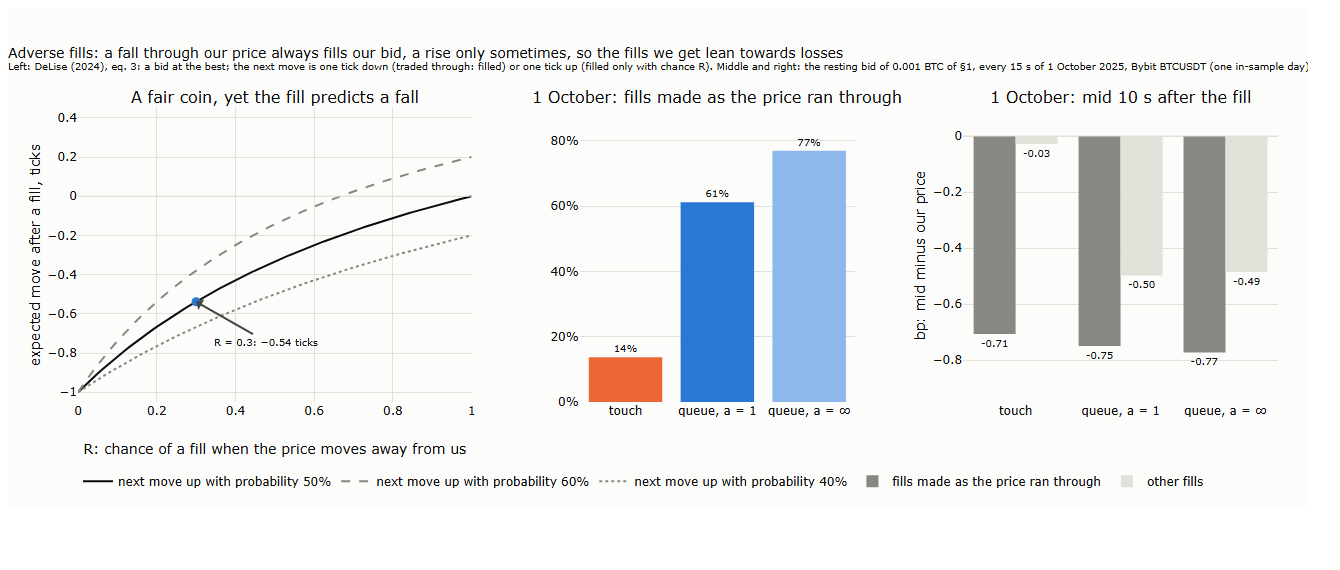

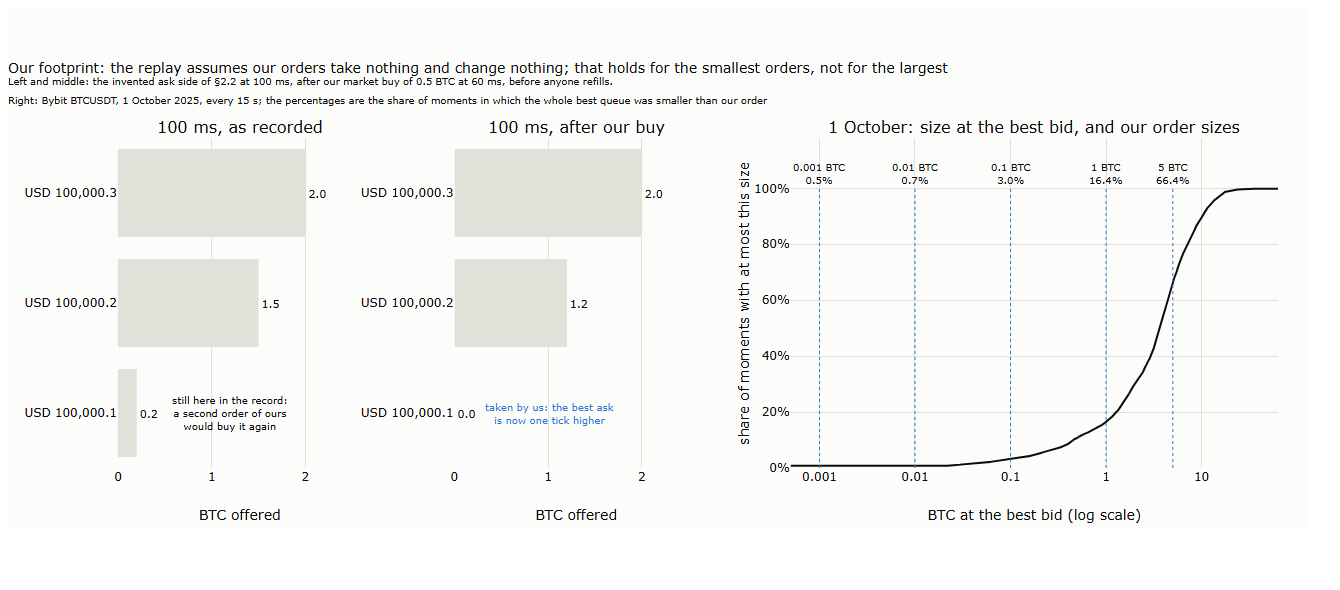

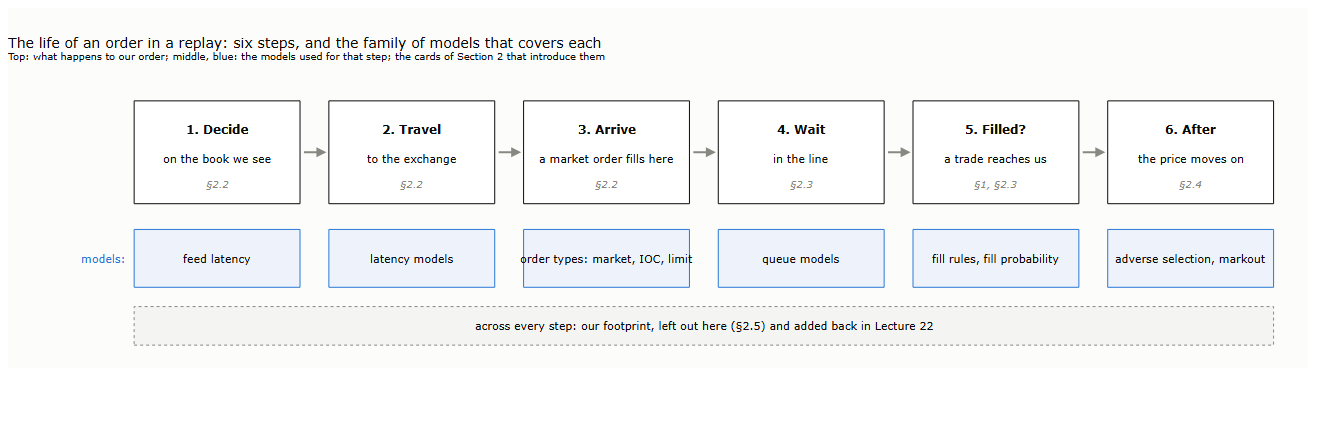

test_bid.py 
 a=1.0: joined behind 1.7 (hand: 1.7), q0 70 (hand: 70), q2 340 (hand: 340), q1 420 (hand: 420) [(60, 1.7), (70, np.float64(1.5)), (100, np.float64(1.2)), (130, np.float64(0.8)), (200, np.float64(0.8)), (250, np.float64(0.6)), (300, np.float64(0.257))]
a=2.0: joined behind 1.7 (hand: 1.7), q0 70 (hand: 70), q2 340 (hand: 340), q1 420 (hand: 420) [(60, 1.7), (70, np.float64(1.5)), (100, np.float64(1.2)), (130, np.float64(0.8)), (200, np.float64(0.8)), (250, np.float64(0.6)), (300, np.float64(0.453))]
a=inf: joined behind 1.7 (hand: 1.7), q0 70 (hand: 70), q2 420 (hand: 420), q1 420 (hand: 420) [(60, 1.7), (70, np.float64(1.5)), (100, np.float64(1.2)), (130, np.float64(0.8)), (200, np.float64(0.8)), (250, np.float64(0.6)), (300, np.float64(0.6)), (340, np.float64(0.1))]
 


test_models.py 
 3000 random sequences; disagreements with the code as published: {1.0: 53, 2.0: 17, 5.0: 1, inf: 0, 'rig': 0}
with hftbacktest's size behind measured after the trades: {1.0: 0, 2.0: 0, 5.0: 0}
 


In [3]:
run("l21_s2_cards.py")
pictures("21_03_replay_card", "21_04_latency_card", "21_05_queue_card", "21_06_queue_models", "21_07_adverse_card", "21_08_footprint_card", "21_09_order_life")
for t in ("test_bid.py", "test_models.py"):
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / "checks" / t), str(SCRIPTS)], capture_output=True, text=True, encoding="utf-8", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    print(t, "\n", p.stdout[-1200:], p.stderr[-800:])

## 3. The replay on our data

Four steps, each with its own script: `l21_s31_net.py` and `l21_s31_clock.py` line up the trades with the book and measure the flow it hides (§3.1); `l21_s32_latency.py` sends taker orders every 10 s through the latency gap (§3.2); `l21_s33_queue.py` holds resting orders in the queue on eight half-hours a day (§3.3), and `l21_s34_sum.py` asks what their fills earn (§3.4).

l21_s3_charts.py : 8 s


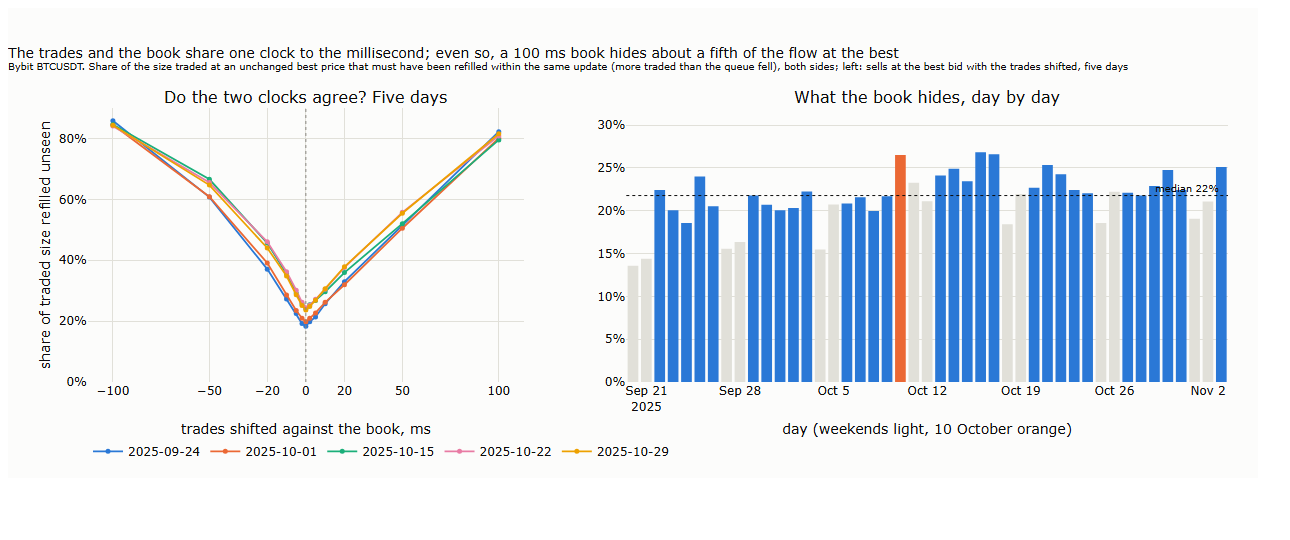

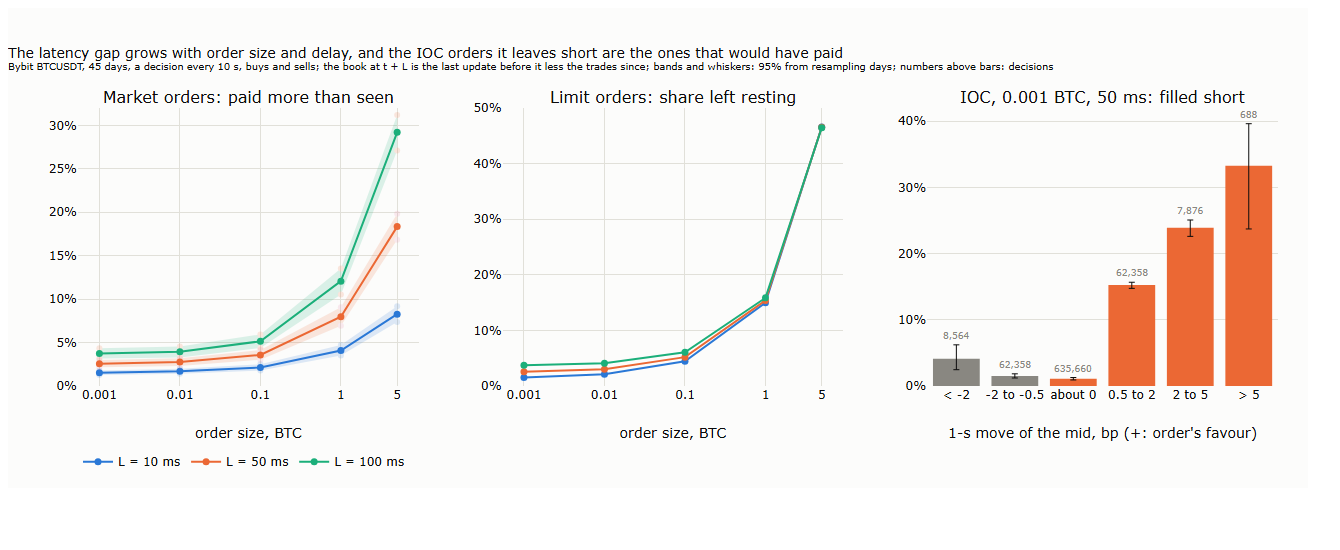

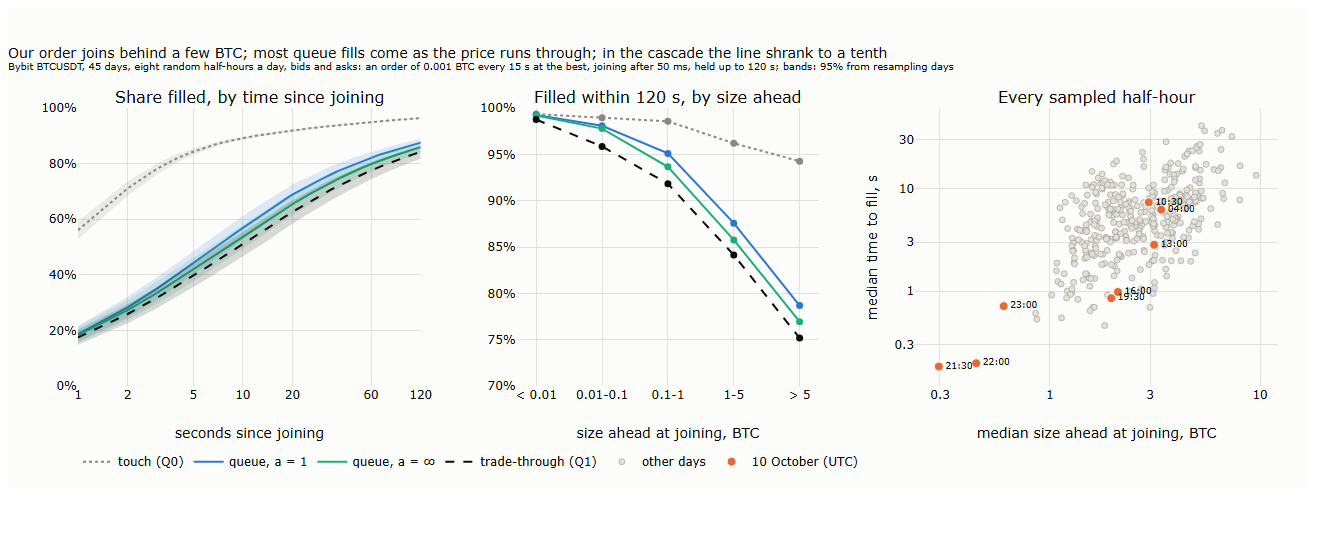

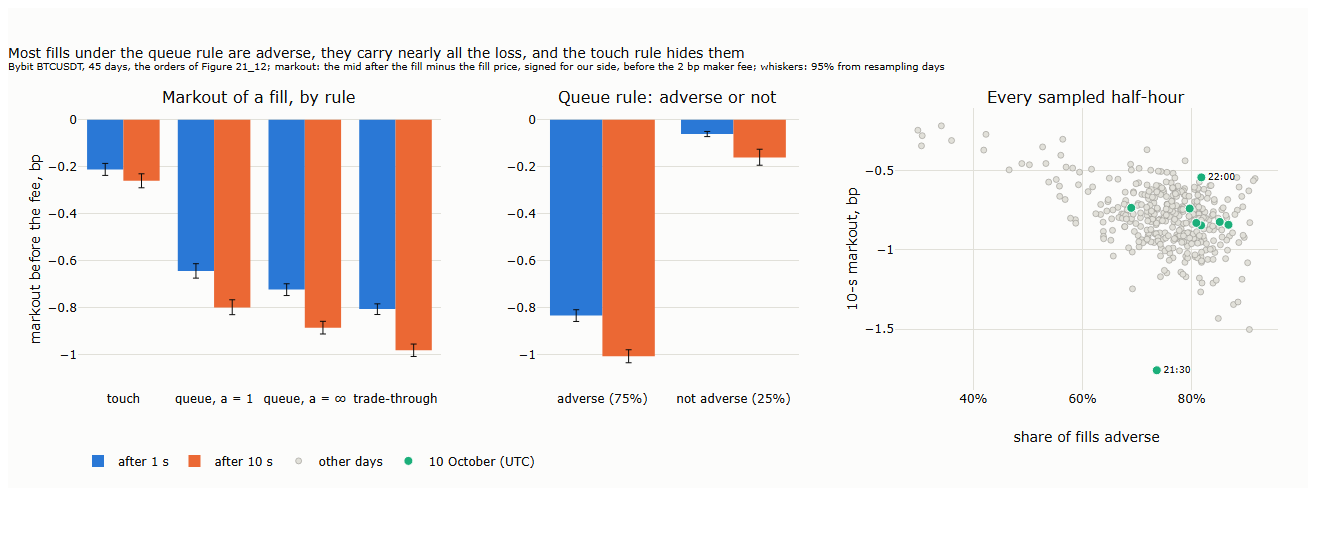

In [4]:
if RUN_ALL:
    for s in ("l21_s31_net.py", "l21_s31_clock.py", "l21_s32_latency.py", "l21_s32_sum.py", "l21_s33_queue.py", "l21_s33_sum.py", "l21_s34_sum.py"): run(s)
elif RUN_CHECK:
    run("l21_s31_net.py", CHECK_DAY); run("l21_s33_queue.py", CHECK_DAY)
    a = shipped("s31", "net_days.parquet").filter(pl.col("day") == CHECK_DAY); b = pl.read_parquet(L.OUT / "s31" / "check_net_days.parquet").filter(pl.col("day") == CHECK_DAY)
    rows = [(f"hidden share, {CHECK_DAY}", a["hidden"].sum() / a["traded"].sum(), b["hidden"].sum() / b["traded"].sum())]
    F = pl.read_parquet(L.OUT / "s33" / f"{CHECK_DAY}.parquet").filter((pl.col("rule") == "Q2 a=1") & pl.col("fill").is_not_null()).with_columns(((pl.col("mid10") - pl.col("price")) / pl.col("price").abs() * 1e4).alias("m10"))
    H = shipped("s34", "halfhours.parquet").filter(pl.col("day") == CHECK_DAY)
    rows += [("held orders, queue rule: fills", H["fills"].sum(), F.height), ("10-s markout, bp", (H["m10"] * H["fills"]).sum() / H["fills"].sum(), F["m10"].mean())]
    display(compare(rows))
run("l21_s3_charts.py")
pictures("21_10_hidden_flow", "21_11_latency_data", "21_12_queue_data", "21_13_adverse_data")

In [5]:
display(table("s32", "size.parquet").filter(pl.col("L") == 50).select("S", "n", "empty", "slip", "worse", "short"))
display(table("s33_sum", "through.parquet"))
display(table("s34", "rules.parquet").select("rule", "fills", "adverse", "m1", "m10"))
display(table("s34", "split.parquet").filter(pl.col("rule") == "Q2 a=1").select("adverse_fill", "fills", "m1", "m10"))

S,n,empty,slip,worse,short
f64,i64,i64,f64,f64,f64
0.001,777504,4,0.003119,0.025538,0.025532
0.01,777504,5,0.003983,0.027511,0.033556
0.1,777504,5,0.004276,0.03577,0.069313
1.0,777504,9,0.003806,0.079763,0.25048
5.0,777504,132,0.002786,0.183478,0.757774


rule,fills,through
str,u32,f64
"""Q2 a=1""",75635,0.635282
"""Q2 a=2""",74691,0.72743
"""Q2 a=20""",74236,0.770138
"""Q2 a=5""",74346,0.757276
"""Q2 a=inf""",74229,0.777118


rule,fills,adverse,m1,m10
str,i64,f64,f64,f64
"""Q0""",83244,0.262397,-0.211242,-0.25921
"""Q1""",72774,0.979993,-0.805594,-0.980844
"""Q2 a=1""",75635,0.754452,-0.643426,-0.798886
"""Q2 a=2""",74691,0.835429,-0.702304,-0.862426
"""Q2 a=20""",74236,0.864257,-0.722545,-0.884365
"""Q2 a=5""",74346,0.858688,-0.718538,-0.879813
"""Q2 a=inf""",74229,0.864756,-0.722845,-0.884868


adverse_fill,fills,m1,m10
bool,i64,f64,f64
true,57063,-0.833041,-1.006757
false,18572,-0.06083,-0.160196


## 4. Does the replay tell the truth?

The quoting runs of `l21_mm.py` feed H1, H2, H3 and H5 and the comparison of the two quoters (§4.1, §4.4). `l21_s4_h4.py` holds the real small fills against the replay's, `l21_s4_h679.py` runs the jobs of H6, H7 and H9, and `l21_s4_h8.py` measures the reaction to size. `l21_s4_verdicts.py` brings the p-values together under the Benjamini-Hochberg procedure at 5%.

l21_s4_charts.py : 5 s


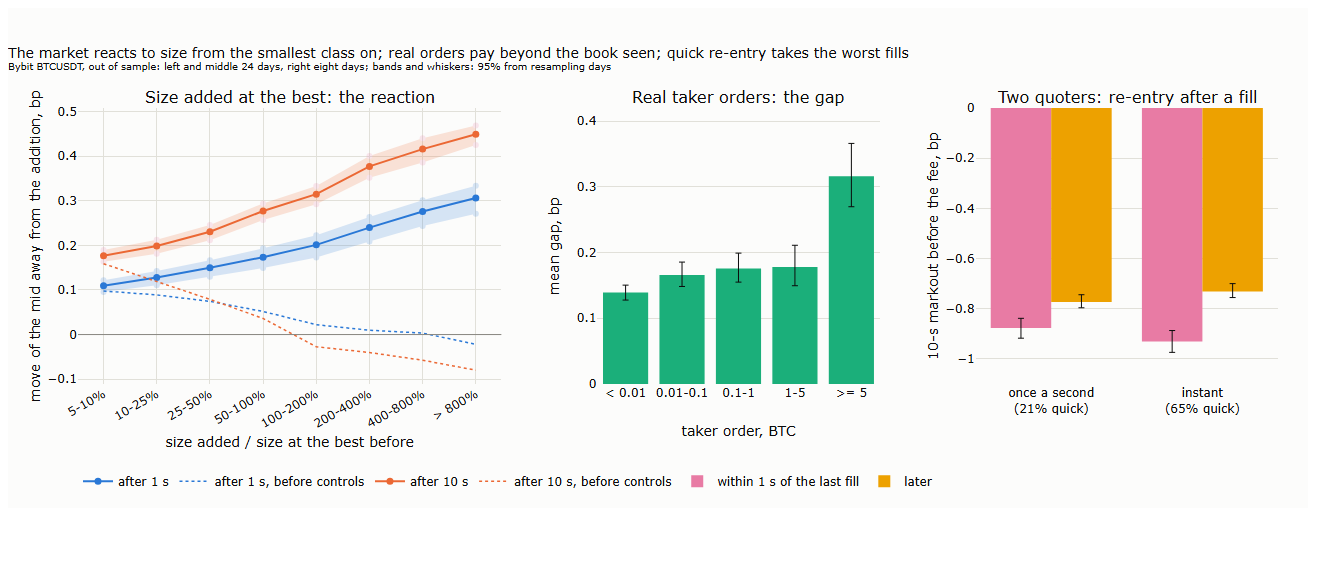

test,p,limit,holds
str,f64,f64,bool
"""H1""",0.0,0.005,true
"""H2""",0.0,0.01,true
"""H4""",0.0,0.015,true
"""H5""",0.0,0.02,true
"""H7""",0.0,0.025,true
"""H8""",0.0,0.03,true
"""H9b markout""",0.0,0.035,true
"""H6b loss""",0.022222,0.04,true
"""H9a fills""",0.038,0.045,true


In [6]:
if RUN_ALL:
    run("l21_mm.py"); run("l21_mm.py", "--tests"); run("l21_s4_tests.py"); run("l21_s4_h4.py"); run("l21_s4_h8.py")
    for j in ("h7", "h9", "h6"): run("l21_s4_h679.py", j)
    for j in ("quoters", "rest"): run("l21_s4_extras.py", j)
    run("l21_s4_verdicts.py")
elif RUN_CHECK:
    run("l21_s4_h679.py", "h6", CHECK_DAY)
    a = shipped("s4", "h6.parquet").filter(pl.col("day") == CHECK_DAY)
    b = pl.read_parquet(L.OUT / "s4" / "h6" / f"{CHECK_DAY}.parquet").filter(pl.col("filled")).with_columns(((pl.col("mid10") - pl.col("price")) / pl.col("price").abs() * 1e4).alias("m10"))
    rows = []
    for q in ("instant", "1s"):
        x, y = a.filter(pl.col("quoter") == q), b.filter(pl.col("quoter") == q)
        rows += [(f"{q}: fills", x["fills"][0], y.height), (f"{q}: adverse", x["adverse"][0], y["adverse"].mean()), (f"{q}: 10-s markout, bp", x["m10"][0], y["m10"].mean())]
    display(compare(rows))
run("l21_s4_charts.py")
pictures("21_14_tests")
display(table("s4", "verdicts.parquet"))

In [7]:
display(table("s4", "h1235.parquet").select("test", "question", "a", "b", "diff", "lo", "hi", "p"))
display(table("s4", "h3.parquet").filter(pl.col("L") == 50).select("rule", "L", "fills", "m10", "m10_fee"))
display(table("s4", "h4_test.parquet").select("real", "replay", "diff", "lo", "hi", "p", "real_fills"))
display(table("s4", "h7.parquet").select("cls", "orders", "gap", "lo", "hi", "median", "share_nonzero", "unpriced"))
display(table("s4", "h8_test.parquet").filter(pl.col("x") == "x >= 100%").select("h", "n", "net", "lo", "hi", "p", "netb", "raw"))
display(table("s4", "h9.parquet").select("orders", "q2", "q1", "missed_fills", "p_fill", "p_markout"))
display(table("s4", "quoters.parquet").filter((pl.col("rule") == "Q2 a=1") & (pl.col("L") == 50)).select("quoter", "per_hour", "adverse", "m10"))
display(table("s4", "reentry.parquet").select("quoter", "quick", "share", "adverse", "m10"))

test,question,a,b,diff,lo,hi,p
str,str,f64,f64,f64,f64,f64,f64
"""H1""","""touch above queue""",-0.293167,-0.762332,0.469165,0.457481,0.478876,0.0
"""H1b""","""queue above trade-through""",-0.762332,-0.928357,0.166025,0.155124,0.179574,0.0
"""H2""","""non-adverse above adverse""",-0.052305,-0.929865,0.87756,0.849011,0.902278,0.0
"""H5""","""other times above the clock moments""",-0.760961,-0.916124,0.155163,0.101357,0.204337,0.0


rule,L,fills,m10,m10_fee
str,i64,u32,f64,f64
"""Q2 a=1""",50,769286,-0.860295,-2.860295
"""Q2 a=inf""",50,712122,-0.906565,-2.906565


real,replay,diff,lo,hi,p,real_fills
f64,f64,f64,f64,f64,f64,i64
-0.118483,-0.762332,-0.64385,-0.658193,-0.62451,0.0,2735006


cls,orders,gap,lo,hi,median,share_nonzero,unpriced
str,i64,f64,f64,f64,f64,f64,i64
"""< 0.01""",12000,0.139076,0.127717,0.150452,-0.0,0.459083,0
"""0.01-0.1""",12000,0.165743,0.148393,0.185523,0.0,0.399333,0
"""0.1-1""",12000,0.175916,0.155055,0.199128,-0.0,0.498167,0
"""1-5""",12000,0.178059,0.149537,0.211092,-0.0,0.58025,0
""">= 5""",50103,0.316072,0.269756,0.366098,4.1518e-12,0.7475,3192


h,n,net,lo,hi,p,netb,raw
str,i64,f64,f64,f64,f64,f64,f64
"""1s""",1416614,0.247131,0.215294,0.272027,0.0,0.236172,0.005469
"""10s""",1416614,0.377415,0.353035,0.396266,0.0,0.370967,-0.047863


orders,q2,q1,missed_fills,p_fill,p_markout
i64,f64,f64,i64,f64,f64
11512,0.477502,0.477154,4,0.038,0.0


quoter,per_hour,adverse,m10
str,f64,f64,f64
"""1s""",1796.666667,0.778586,-0.794771
"""instant""",4006.697917,0.822051,-0.860295


quoter,quick,share,adverse,m10
str,bool,f64,f64,f64
"""1s""",false,0.792086,0.738031,-0.773137
"""1s""",true,0.207914,0.933089,-0.877192
"""instant""",false,0.35198,0.664136,-0.731443
"""instant""",true,0.64802,0.907824,-0.930283


## 5. 10 October

`l21_s5.py` reads the runs already made and describes the window 20:50 to 22:50 UTC against the same window on the other 44 days. No new replay is needed. The tables below give the numbers of §5: the two quoters, split into the 10 s after each fill and the position carried afterwards, and our taker orders.

l21_s5_charts.py : 3 s


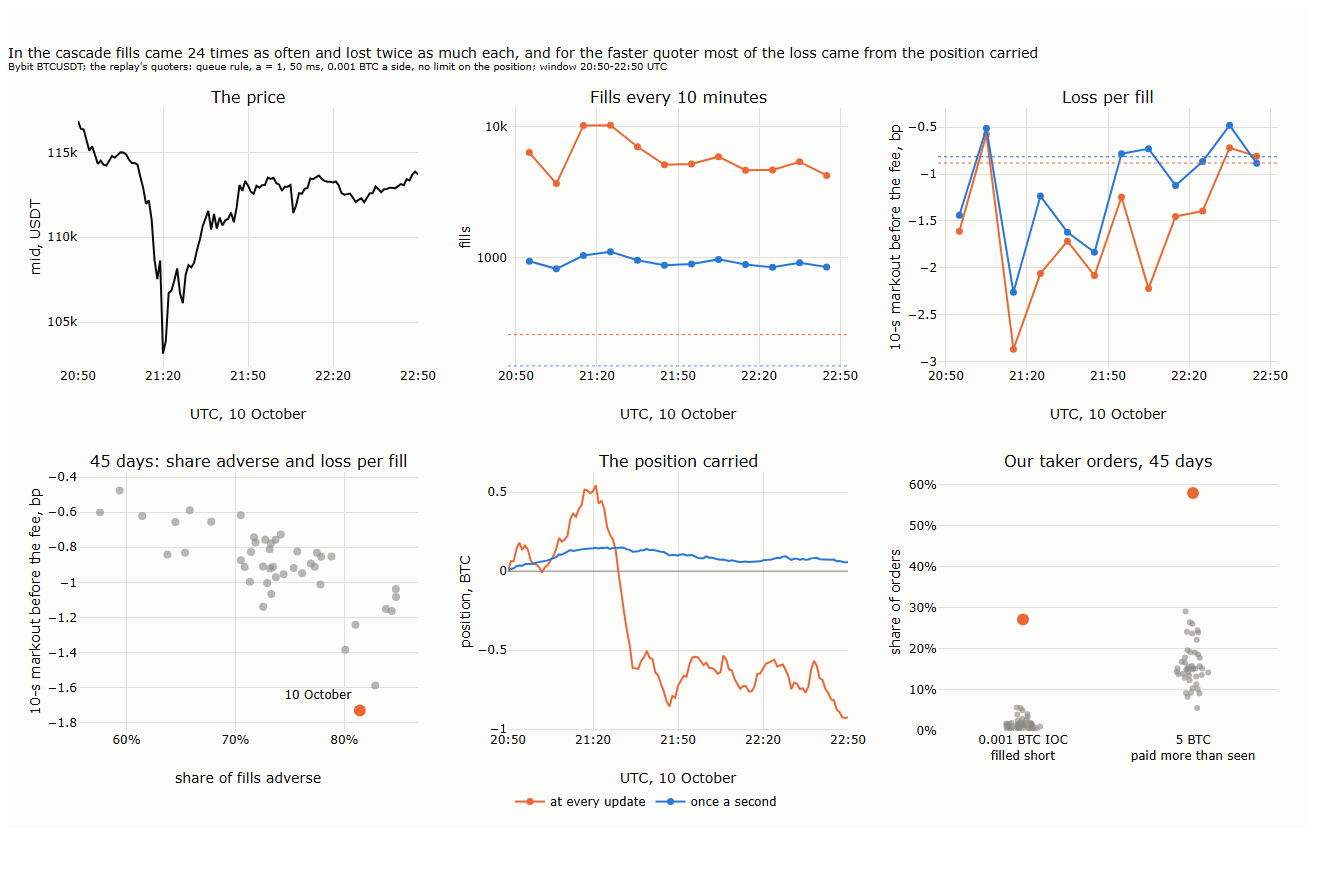

quoter,fills,adverse,m10,m10_sd,bp_10s,bp_position,bp_total,usdt,max_pos
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""instant""",72759,0.814195,-1.730631,40.987197,-1.721893,-7.262185,-8.984078,-7295.17515,0.944
"""1s""",11042,0.774226,-1.16908,32.886708,-1.162912,-1.781993,-2.944905,-364.5894,0.152


quoter,fills,adverse,m10,m10_sd,bp_10s,bp_position,bp_total,usdt,max_pos
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""instant""",3073.5,0.732796,-0.883197,1.839702,-0.883178,0.168931,-0.715481,-22.915625,0.189
"""1s""",1765.5,0.685283,-0.815759,1.742317,-0.81569,0.368001,-0.438719,-8.51425,0.1155


S,empty,slip,worse,short,spread,move10
f32,u32,f32,f64,f64,f32,f32
0.001,0,0.138966,0.271528,0.271528,0.113499,16.09016
0.01,0,0.156986,0.282639,0.297917,0.113499,16.09016
0.1,0,0.175771,0.324306,0.377083,0.113499,16.09016
1.0,2,0.188077,0.488889,0.692361,0.113499,16.09016
5.0,86,0.11173,0.579861,0.941667,0.113499,16.09016


S,slip,worse,short,spread,move10,worse_max,short_max,empty
f32,f32,f64,f64,f32,f32,f64,f64,u32
0.001,0.001558,0.014583,0.014583,0.009057,0.916403,0.056944,0.056944,0
0.01,0.001937,0.016319,0.018403,0.009057,0.916403,0.064583,0.080556,0
0.1,0.001979,0.022917,0.062153,0.009057,0.916403,0.085417,0.142361,0
1.0,0.002064,0.062153,0.280903,0.009057,0.916403,0.170833,0.511111,0
5.0,0.001561,0.152083,0.821528,0.009057,0.916403,0.290972,0.950694,4


when,rule,n,filled,m10
str,str,u32,f64,f64
"""43""","""Q0""",240,0.995833,-0.864032
"""43""","""Q1""",240,0.975,-2.084678
"""43""","""Q2 a=1""",240,0.979167,-1.758395
"""43""","""Q2 a=2""",240,0.975,-1.850743
"""43""","""Q2 a=20""",240,0.975,-1.864314
"""43""","""Q2 a=5""",240,0.975,-1.855998
"""43""","""Q2 a=inf""",240,0.975,-1.869887
"""44""","""Q0""",240,0.991667,-0.399751
"""44""","""Q1""",240,0.983333,-0.666014


step,fills,adverse,m10,pos
i64,i64,f64,f64,f64
0,6345,0.852167,-1.610301,0.043
1,3675,0.88,-0.577159,0.2
2,10254,0.747708,-2.87038,0.506
3,10269,0.776609,-2.062606,-0.153
4,7028,0.763375,-1.716994,-0.549
5,5125,0.764878,-2.084556,-0.726
6,5198,0.791073,-1.24536,-0.58
7,5906,0.845919,-2.223165,-0.684
8,4656,0.893041,-1.45248,-0.614


In [8]:
if RUN_ALL: run("l21_s5.py", show=True)
run("l21_s5_charts.py")
pictures("21_15_cascade")
D = table("s5", "days.parquet").with_columns(*[(pl.col(c) / pl.col("volume_usdt") * 1e4).alias(n) for c, n in (("usdt_10s", "bp_10s"), ("usdt_held", "bp_position"), ("usdt", "bp_total"))])
COLS = ["fills", "adverse", "m10", "m10_sd", "bp_10s", "bp_position", "bp_total", "usdt", "max_pos"]
display(D.filter(pl.col("day") == CRASH).select("quoter", *COLS))
display(D.filter(pl.col("day") != CRASH).group_by("quoter").agg(pl.col(COLS).median()).sort("quoter", descending=True))
T = table("s5", "taker.parquet").filter(pl.col("L") == 50)
display(T.filter(pl.col("day") == CRASH).sort("S").select("S", "empty", "slip", "worse", "short", "spread", "move10"))
display(T.filter(pl.col("day") != CRASH).group_by("S").agg(pl.col("slip", "worse", "short", "spread", "move10").median(), pl.col("worse", "short").max().name.suffix("_max"), pl.col("empty").sum()).sort("S"))
display(table("s5", "rules.parquet"))
display(table("s5", "path.parquet").filter(pl.col("quoter") == "instant").select("step", "fills", "adverse", "m10", "pos"))

## 6. A test of your own: the position against the fills

An example of what Section 5 leaves open. Over all 45 evenings, how large is the part of the result that comes from the position carried, against the part in the 10 s after each fill? Is the result of an evening explained by its largest position? From here, the exercise of §6.3 is to rerun the quoters with a limit on the position (`l21_mm.chain` is where the next order is sent).

In [9]:
for q in ("instant", "1s"):
    o = D.filter((pl.col("quoter") == q) & (pl.col("day") != CRASH))
    print(q, "| other 44 evenings: position's part, bp: min", round(o["bp_position"].min(), 2), "median", round(o["bp_position"].median(), 2), "max", round(o["bp_position"].max(), 2),
          "| correlation of |position's part, USDT| with the largest position:", round(float(np.corrcoef(o["usdt_held"].abs(), o["max_pos"])[0, 1]), 2))

instant | other 44 evenings: position's part, bp: min -3.92 median 0.17 max 4.86 | correlation of |position's part, USDT| with the largest position: 0.73
1s | other 44 evenings: position's part, bp: min -3.82 median 0.37 max 6.92 | correlation of |position's part, USDT| with the largest position: 0.55
